# Classificação de Leucemia Linfoblástica Aguda (C-NMC 2019) com Deep Learning

**SIN 393 – Introdução à Visão Computacional (2026)** · UFV – Campus Rio Paranaíba · Prof. João Fernando Mari

**Dataset:** [Leukemia Classification (C-NMC 2019) – Kaggle](https://www.kaggle.com/datasets/andrewmvd/leukemia-classification)

**Problema:** classificação binária de imagens de células únicas segmentadas de esfregaço sanguíneo em
**ALL** (célula leucêmica / linfoblasto) e **HEM** (célula normal / hematogônia).

**Questão experimental:** *comparação entre arquiteturas* — ResNet50, DenseNet121 e EfficientNet-B3, treinadas
sob o **mesmo protocolo** (mesmos dados, aumento de dados, hiperparâmetros e semente), avaliadas no mesmo conjunto de teste
e comparadas com métricas, custo computacional e **teste de McNemar** para significância estatística.

### Roteiro do notebook
| Etapa | Conteúdo |
|---|---|
| 0 | Revisão da literatura e escolha dos modelos |
| 1 | Instalação de dependências e importações |
| 2 | Configurações e reprodutibilidade |
| 3 | Download do dataset |
| 4 | Indexação e análise exploratória |
| 5 | Divisão treino / validação / teste (hold-out estratificado) |
| 6 | Aumento de dados (data augmentation) e pré-processamento |
| 7 | Datasets e DataLoaders |
| 8 | Definição das arquiteturas (torchvision) |
| 9 | Funções de treino e validação |
| 10 | Treinamento e salvamento dos modelos (`.pth`) |
| 11 | Curvas de aprendizado |
| 12 | Avaliação no teste: Classification Report, matriz de confusão e métricas |
| 13 | Análise qualitativa: amostras corretas e incorretas por arquitetura |
| 14 | Comparação entre arquiteturas (McNemar) |

## 0. Revisão da literatura e escolha dos modelos

O C-NMC 2019 (*Classification of Normal vs Malignant Cells in B-ALL White Blood Cancer Microscopic Images*) foi
disponibilizado pelo SBILab no desafio do ISBI 2019. O conjunto de treino possui **10.661 imagens** (7.272 ALL e 3.389 HEM)
de **73 indivíduos**, organizadas em 3 *folds* separados por paciente. O conjunto *preliminary test* tem **1.867 imagens
rotuladas** (1.219 ALL e 648 HEM) de **28 indivíduos que não aparecem no treino**. O conjunto *final test* (2.586 imagens)
não tem rótulos públicos.

Principais arquiteturas usadas no dataset e disponíveis no `torchvision`:

| Família | Trabalhos no C-NMC 2019 | Resultado relatado |
|---|---|---|
| **EfficientNet (B0–B3)** | Ahmed (2025) comparou ResNet50, ResNet101 e EfficientNet-B0/B1/B3 com *transfer learning* e aumento de dados; benchmark *leakage-aware* (arXiv 2606.24944, 2026) com EfficientNet-B0/B1, ViT-Tiny, SVM e LightGBM | EfficientNet-B3: **F1 = 94,30%**, acc. 92,02%, AUC 94,79% (Ahmed, 2025). Na avaliação com pacientes disjuntos, as EfficientNets foram os únicos modelos com sensibilidade e especificidade equilibradas |
| **ResNet (ResNet50/101, ResNeXt)** | Prellberg & Kramer (2019), ResNeXt50; *ResNet + neighborhood correction* (Pan et al., 2019, 1º lugar no desafio); Ahmed (2025) | F1 ponderado de 88,91% no teste oficial (Prellberg & Kramer); F1 ≈ 92,5% (ResNet TL + NC) |
| **DenseNet (DenseNet121)** | Fusão de características DenseNet121-ResNet50-MobileNet (Diagnostics, 2023); comparações InceptionV3/DenseNet/InceptionResNetV2 | Fusão com RF: acc. 98,8% (divisão por imagem). DenseNet121 aparece com frequência como *backbone* forte |
| VGG16 | Desafio C-NMC (TL e treino do zero) | F1 ≈ 91,7–92,6%, porém com ~138M de parâmetros |
| ViT / Swin | Benchmarks recentes | ViT-Tiny teve desempenho inferior às CNNs com pacientes disjuntos (acc. 67,8%) |

**Modelos escolhidos (3 melhores do `torchvision` segundo a literatura):**
1. **EfficientNet-B3** (`torchvision.models.efficientnet_b3`) — melhor F1 relatado com *transfer learning*.
2. **ResNet50** (`torchvision.models.resnet50`) — base da solução vencedora do desafio e *baseline* mais usado.
3. **DenseNet121** (`torchvision.models.densenet121`) — boa reutilização de características com poucos parâmetros.

VGG16 foi descartada por ter custo muito maior para desempenho semelhante. ViTs foram descartados porque, neste dataset relativamente pequeno,
tiveram desempenho inferior ao das CNNs.

> **Atenção ao vazamento de dados (data leakage):** vários trabalhos com acurácia acima de 97% fazem divisão aleatória **por imagem**.
> Assim, células de um mesmo paciente aparecem no treino e no teste, e o modelo aprende pistas do paciente. Por isso, este projeto usa
> o conjunto *preliminary test* (pacientes não vistos) como **teste independente**. Os resultados esperados são mais baixos, mas
> mais confiáveis.

**Referências principais**
- Gupta, A.; Gupta, R. *ALL Challenge dataset of ISBI 2019*. The Cancer Imaging Archive, 2019. DOI: 10.7937/tcia.2019.dc64i46r
- Ahmed, F. *Transfer Learning with EfficientNet for Accurate Leukemia Cell Classification*. arXiv:2508.06535, 2025.
- *A Leakage-Aware Comparative Benchmark of ML, DL and Transformer Models for Reliable Leukemia Detection*. arXiv:2606.24944, 2026.
- Prellberg, J.; Kramer, O. *Acute Lymphoblastic Leukemia Classification from Microscopic Images using CNNs*. arXiv:1906.09020, 2019.
- Ahmed, I. A. et al. *Hybrid techniques for diagnosing ALL ... C-NMC 2019 and ALL-IDB2*. Diagnostics, 13(6):1026, 2023.
- Tan, M.; Le, Q. *EfficientNet: Rethinking Model Scaling for CNNs*. ICML, 2019. · He, K. et al. *Deep Residual Learning*. CVPR, 2016. · Huang, G. et al. *Densely Connected Convolutional Networks*. CVPR, 2017.

## 1. Instalação de dependências e importações

In [4]:
# No Google Colab, torch/torchvision/sklearn já vêm instalados; apenas garantimos o kagglehub.
import importlib, subprocess, sys
for pkg in ["kagglehub", "seaborn", "tqdm"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

In [5]:
import os, json, time, random, shutil, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import models
import torchvision.transforms as T

from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
                             precision_recall_fscore_support, f1_score, roc_auc_score,
                             roc_curve, balanced_accuracy_score)
from scipy.stats import binomtest

warnings.filterwarnings("ignore", category=UserWarning)
print(f"PyTorch {torch.__version__} | torchvision {torchvision.__version__}")

PyTorch 2.14.1+cu130 | torchvision 0.29.1+cu130


## 2. Configurações e reprodutibilidade

Todos os modelos usam **os mesmos hiperparâmetros**, para que a comparação entre arquiteturas seja justa. A resolução de entrada
(224×224) é a mesma para os três modelos.

`QUICK_RUN = True` executa uma versão reduzida (poucas imagens e 1 época) só para testar o pipeline de ponta a ponta.

In [ ]:
# ---------------- Hiperparâmetros e opções ----------------
SEED          = 42
IMG_SIZE      = 224          
BATCH_SIZE    = 32
EPOCHS        = 25
LR            = 1e-4
WEIGHT_DECAY  = 1e-4
PATIENCE      = 6            # early stopping (épocas sem melhora do F1-macro de validação)
VAL_SIZE      = 0.15        
TEST_SIZE     = 0.15         # usado apenas se TEST_STRATEGY == "split"
NUM_WORKERS   = 2
PRETRAINED    = True         # transfer learning a partir do ImageNet

# "prelim": teste = C-NMC preliminary test (28 pacientes NÃO vistos no treino)  -> recomendado
# "split" : teste = divisão estratificada aleatória do treino (por imagem; sujeito a vazamento de paciente)
TEST_STRATEGY = "prelim"

MODEL_NAMES = ["resnet50", "densenet121", "efficientnet_b3"]

# Classes: 0 = HEM (normal), 1 = ALL (leucêmica) — CSV oficial
CLASS_NAMES = ["hem", "all"]
CLASS_LABELS = ["HEM (normal)", "ALL (leucêmica)"]

QUICK_RUN = os.environ.get("QUICK_RUN", "0") == "1" 
if QUICK_RUN:
    EPOCHS, PATIENCE, BATCH_SIZE = 1, 1, 8

OUTPUT_DIR = Path("outputs")
DIRS = {k: OUTPUT_DIR / k for k in ["models", "figures", "reports", "samples", "logs"]}
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)


def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def seed_worker(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s); random.seed(s)

set_seed()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
print("Dispositivo:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU")
print("QUICK_RUN:", QUICK_RUN)

config = dict(SEED=SEED, IMG_SIZE=IMG_SIZE, BATCH_SIZE=BATCH_SIZE, EPOCHS=EPOCHS, LR=LR,
              WEIGHT_DECAY=WEIGHT_DECAY, PATIENCE=PATIENCE, VAL_SIZE=VAL_SIZE,
              TEST_STRATEGY=TEST_STRATEGY, MODEL_NAMES=MODEL_NAMES, PRETRAINED=PRETRAINED,
              QUICK_RUN=QUICK_RUN, device=str(DEVICE))
(DIRS["logs"] / "config.json").write_text(json.dumps(config, indent=2))

Dispositivo: cuda | Tesla T4
QUICK_RUN: False


324

## 3. Download do dataset

O download usa o `kagglehub` (sem credenciais para datasets públicos). Para usar uma cópia local, defina a variável de ambiente
`LEUKEMIA_DATA_DIR` apontando para a pasta que contém `C-NMC_Leukemia/`.

In [ ]:
DATA_DIR = os.environ.get("LEUKEMIA_DATA_DIR")
if DATA_DIR is None:
    import kagglehub
    DATA_DIR = kagglehub.dataset_download("andrewmvd/leukemia-classification")
DATA_DIR = Path(DATA_DIR)

train_roots = sorted(p for p in DATA_DIR.rglob("training_data") if p.is_dir())
assert train_roots, f"Pasta 'training_data' não encontrada em {DATA_DIR}"
TRAIN_ROOT = train_roots[0]
CNMC_ROOT = TRAIN_ROOT.parent
print("Raiz do dataset:", CNMC_ROOT)
for p in sorted(CNMC_ROOT.iterdir()):
    print("  ", p.name)

Using Colab cache for faster access to the 'leukemia-classification' dataset.
Raiz do dataset: /kaggle/input/leukemia-classification/C-NMC_Leukemia
   testing_data
   training_data
   validation_data


## 4. Indexação e análise exploratória

- `training_data/fold_{0,1,2}/{all,hem}/*.bmp`: imagens de treino. O nome do arquivo segue o padrão
  `UID_<paciente>_<imagem>_<célula>_<classe>.bmp`, o que permite extrair o identificador do paciente.
- `validation_data/C-NMC_test_prelim_phase_data/*.bmp` + CSV de rótulos: *preliminary test*, rotulado.

In [ ]:
def subject_id(fname: str) -> str:
    # UID_11_10_1_all.bmp -> UID_11 ; UID_H10_43_1_hem.bmp -> UID_H10
    return "_".join(Path(fname).stem.split("_")[:2])

#Treino
recs = []
for p in sorted(TRAIN_ROOT.glob("fold_*/*/*")):
    if p.suffix.lower() not in {".bmp", ".png", ".jpg", ".jpeg"}:
        continue
    cls = p.parent.name.lower()
    if cls not in CLASS_NAMES:
        continue
    recs.append(dict(path=str(p), label=CLASS_NAMES.index(cls), cls=cls,
                     fold=p.parent.parent.name, subject=subject_id(p.name)))
train_full_df = pd.DataFrame(recs)

#Preliminary test (rotulado)
prelim_df = None
csvs = [c for c in CNMC_ROOT.rglob("*.csv") if "prelim" in c.name.lower() or "label" in c.name.lower()]
if csvs:
    lab = pd.read_csv(csvs[0])
    lab.columns = [c.strip() for c in lab.columns]
    name_col = "new_names" if "new_names" in lab.columns else lab.columns[1]
    label_col = "labels" if "labels" in lab.columns else lab.columns[-1]
    pid_col = "Patient_ID" if "Patient_ID" in lab.columns else lab.columns[0]
    first = lab[name_col].iloc[0]
    hits = [h for h in CNMC_ROOT.rglob(first) if "prelim" in str(h.parent).lower()] or list(CNMC_ROOT.rglob(first))
    if hits:
        img_dir = hits[0].parent
        prelim_df = pd.DataFrame(dict(
            path=[str(img_dir / n) for n in lab[name_col]],
            label=lab[label_col].astype(int).values,
            subject=[subject_id(s) for s in lab[pid_col]],
        ))
        prelim_df["cls"] = prelim_df["label"].map(lambda i: CLASS_NAMES[i])
        prelim_df["fold"] = "prelim_test"
        prelim_df = prelim_df[prelim_df["path"].map(os.path.exists)].reset_index(drop=True)

print(f"Treino (folds): {len(train_full_df)} imagens | {train_full_df.subject.nunique()} pacientes")
if prelim_df is not None:
    print(f"Preliminary test: {len(prelim_df)} imagens | {prelim_df.subject.nunique()} pacientes")
    inter = set(train_full_df.subject) & set(prelim_df.subject)
    print("Pacientes em comum treino x prelim:", len(inter))

Treino (folds): 10661 imagens | 73 pacientes
Preliminary test: 1867 imagens | 28 pacientes
Pacientes em comum treino x prelim: 0


cls,all,hem,total
fold,,,
fold_0,2397,1130,3527
fold_1,2418,1163,3581
fold_2,2457,1096,3553
prelim_test,1219,648,1867


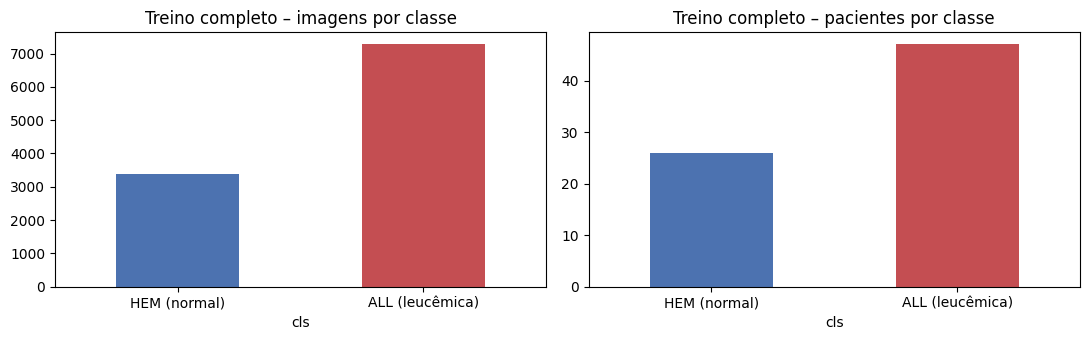

Razão ALL/HEM no treino: 2.15 -> dataset desbalanceado (~2:1)


In [ ]:
#Distribuição das classes
summary = train_full_df.groupby(["fold", "cls"]).size().unstack(fill_value=0)
if prelim_df is not None:
    summary.loc["prelim_test"] = prelim_df.cls.value_counts().reindex(summary.columns, fill_value=0)
summary["total"] = summary.sum(axis=1)
display(summary)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
train_full_df.cls.value_counts().reindex(CLASS_NAMES).plot.bar(ax=ax[0], color=["#4C72B0", "#C44E52"])
ax[0].set_title("Treino completo – imagens por classe"); ax[0].set_xticklabels(CLASS_LABELS, rotation=0)
train_full_df.groupby("cls").subject.nunique().reindex(CLASS_NAMES).plot.bar(ax=ax[1], color=["#4C72B0", "#C44E52"])
ax[1].set_title("Treino completo – pacientes por classe"); ax[1].set_xticklabels(CLASS_LABELS, rotation=0)
plt.tight_layout(); plt.savefig(DIRS["figures"] / "distribuicao_classes.png", dpi=150); plt.show()

ratio = (train_full_df.label == 1).sum() / (train_full_df.label == 0).sum()
print(f"Razão ALL/HEM no treino: {ratio:.2f} -> dataset desbalanceado (~2:1)")

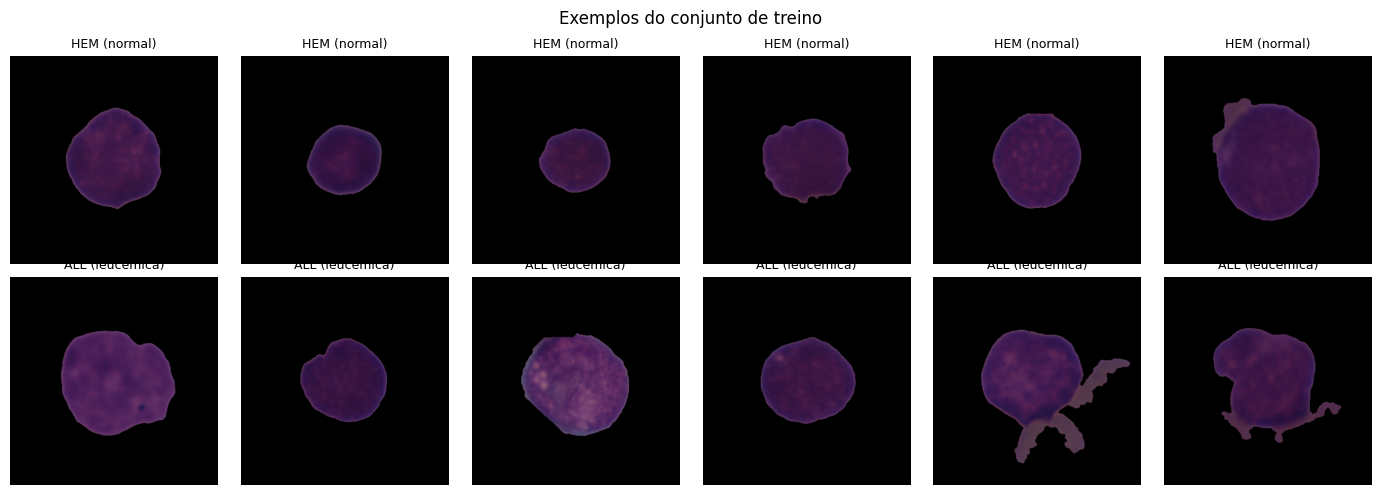

Tamanhos de imagem (amostra): {(450, 450): 200}


In [ ]:
#Exemplos de cada classe e imagens
rng = np.random.RandomState(SEED)
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for r, c in enumerate(CLASS_NAMES):
    sel = train_full_df[train_full_df.cls == c].sample(6, random_state=SEED)
    for k, p in enumerate(sel.path):
        axes[r, k].imshow(Image.open(p).convert("RGB")); axes[r, k].axis("off")
        axes[r, k].set_title(CLASS_LABELS[r], fontsize=9)
plt.suptitle("Exemplos do conjunto de treino"); plt.tight_layout()
plt.savefig(DIRS["figures"] / "exemplos_classes.png", dpi=150); plt.show()

sizes = pd.Series([Image.open(p).size for p in train_full_df.path.sample(min(200, len(train_full_df)), random_state=SEED)])
print("Tamanhos de imagem (amostra):", sizes.value_counts().to_dict())

## 5. Divisão treino / validação / teste (hold-out)

- **Teste:** com `TEST_STRATEGY = "prelim"`, o teste é o *preliminary test* oficial (28 pacientes **não vistos**), o que evita
  vazamento de paciente. Com `"split"`, o teste sai do treino via `train_test_split` estratificado.
- **Treino / validação:** `train_test_split` do scikit-learn, **estratificado** pela classe e com **semente fixa** (`SEED = 42`).
- O conjunto de teste é usado **apenas na avaliação final** (etapa 12). A seleção do melhor checkpoint e o *early stopping*
  usam somente a validação.

In [ ]:
if TEST_STRATEGY == "prelim" and prelim_df is not None:
    trainval_df, test_df = train_full_df, prelim_df
else:
    if TEST_STRATEGY == "prelim":
        print("Preliminary test não encontrado -> usando divisão estratificada.")
    trainval_df, test_df = train_test_split(train_full_df, test_size=TEST_SIZE,
                                            stratify=train_full_df.label, random_state=SEED)

train_df, val_df = train_test_split(trainval_df, test_size=VAL_SIZE,
                                    stratify=trainval_df.label, random_state=SEED)

if QUICK_RUN:
    sub = lambda d, n: pd.concat([g.sample(min(n, len(g)), random_state=SEED) for _, g in d.groupby("label")])
    train_df, val_df, test_df = sub(train_df, 32), sub(val_df, 16), sub(test_df, 24)

train_df, val_df, test_df = [d.reset_index(drop=True) for d in (train_df, val_df, test_df)]

split_summary = pd.DataFrame({n: d.cls.value_counts().reindex(CLASS_NAMES) for n, d in
                              [("treino", train_df), ("validação", val_df), ("teste", test_df)]}).T
split_summary["total"] = split_summary.sum(axis=1)
split_summary["% ALL"] = (100 * split_summary["all"] / split_summary["total"]).round(1)
display(split_summary)
for n, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    d.to_csv(DIRS["logs"] / f"split_{n}.csv", index=False)

cls,hem,all,total,% ALL
treino,2880,6181,9061,68.2
validação,509,1091,1600,68.2
teste,648,1219,1867,65.3


## 6. Aumento de dados (data augmentation) e pré-processamento

As imagens são células únicas já segmentadas, centralizadas e sobre **fundo preto** (450×450 px, BMP). Cada transformação foi
escolhida para simular variações **que não mudam o rótulo** e que ocorrem na prática:

| Transformação | Parâmetros | Justificativa |
|---|---|---|
| `RandomHorizontalFlip` / `RandomVerticalFlip` | p = 0,5 | Uma célula na lâmina não tem orientação canônica: o espelhamento não muda a morfologia (forma do núcleo, relação núcleo/citoplasma). |
| `RandomRotation` | 0–180°, preenchimento preto | Mesma invariância à orientação. O preenchimento preto coincide com o fundo, então não cria artefatos. |
| `RandomAffine` | translação ±5%, escala 0,95–1,05 | Simula pequenas diferenças de centralização da segmentação. A **escala é limitada** porque o tamanho da célula é uma característica discriminativa (linfoblastos tendem a ser maiores); escalas grandes poderiam apagar essa pista. |
| `ColorJitter` | brilho/contraste/saturação 0,2; matiz 0,02 | O C-NMC tem forte **variação de coloração** entre lâminas e pacientes. Também foi aplicada normalização de coloração no dataset original, mas variações residuais permanecem. O jitter ajuda o modelo a generalizar para **pacientes não vistos**. A matiz é pequena para não alterar a cor da coloração. |
| `GaussianBlur` | kernel 3, σ 0,1–1,0, p = 0,2 | Simula pequenas variações de **foco do microscópio**. |

**Evitadas de propósito:** recortes agressivos (`RandomResizedCrop` com escala pequena), que cortariam a célula ou mudariam o tamanho
aparente; deformações elásticas fortes e *cutout*/*erasing*, que alterariam a forma do núcleo, a principal pista diagnóstica.

**Desbalanceamento (~2:1):** além do aumento de dados, a função de perda usa **pesos inversamente proporcionais à frequência
das classes**. O aumento de dados é aplicado **somente ao treino**; validação e teste recebem só redimensionamento e normalização ImageNet.

In [ ]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tf = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomVerticalFlip(p=0.5),
    T.RandomRotation(degrees=180, fill=0),
    T.RandomAffine(degrees=0, translate=(0.05, 0.05), scale=(0.95, 1.05), fill=0),
    T.RandomApply([T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.02)], p=0.8),
    T.RandomApply([T.GaussianBlur(kernel_size=3, sigma=(0.1, 1.0))], p=0.2),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])

eval_tf = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])

def denorm(t):
    x = t.clone().cpu() * torch.tensor(STD)[:, None, None] + torch.tensor(MEAN)[:, None, None]
    return x.clamp(0, 1).permute(1, 2, 0).numpy()

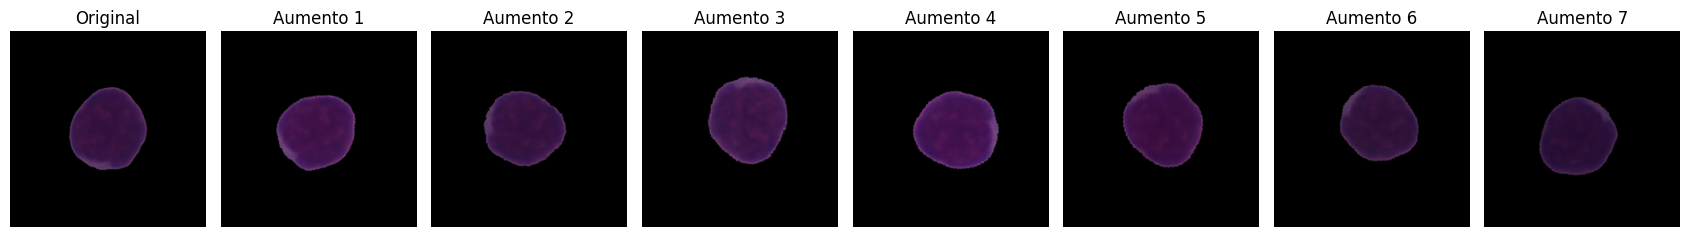

In [ ]:
# Visualização do aumento de dados
set_seed()
ex_path = train_df[train_df.label == 1].path.iloc[0]
ex_img = Image.open(ex_path).convert("RGB")
fig, axes = plt.subplots(1, 8, figsize=(17, 2.6))
axes[0].imshow(ex_img.resize((IMG_SIZE, IMG_SIZE))); axes[0].set_title("Original")
for k in range(1, 8):
    axes[k].imshow(denorm(train_tf(ex_img))); axes[k].set_title(f"Aumento {k}")
for a in axes: a.axis("off")
plt.tight_layout(); plt.savefig(DIRS["figures"] / "data_augmentation.png", dpi=150); plt.show()

## 7. Datasets e DataLoaders

In [ ]:
class CellDataset(Dataset):
    def __init__(self, df, transform):
        self.paths = df.path.tolist()
        self.labels = df.label.astype(int).tolist()
        self.transform = transform
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        return self.transform(img), self.labels[i], i

def make_loader(df, tf, shuffle):
    g = torch.Generator(); g.manual_seed(SEED)
    return DataLoader(CellDataset(df, tf), batch_size=BATCH_SIZE, shuffle=shuffle,
                      num_workers=NUM_WORKERS, pin_memory=DEVICE.type == "cuda",
                      worker_init_fn=seed_worker, generator=g,
                      persistent_workers=NUM_WORKERS > 0)

train_loader = make_loader(train_df, train_tf, shuffle=True)
val_loader   = make_loader(val_df,   eval_tf,  shuffle=False)
test_loader  = make_loader(test_df,  eval_tf,  shuffle=False)


counts = np.bincount(train_df.label, minlength=len(CLASS_NAMES))
class_weights = torch.tensor(len(train_df) / (len(CLASS_NAMES) * counts), dtype=torch.float32)
print("Contagem por classe (treino):", dict(zip(CLASS_NAMES, counts)))
print("Pesos de classe:", dict(zip(CLASS_NAMES, class_weights.numpy().round(3))))
print(f"Batches -> treino: {len(train_loader)} | val: {len(val_loader)} | teste: {len(test_loader)}")

Contagem por classe (treino): {'hem': np.int64(2880), 'all': np.int64(6181)}
Pesos de classe: {'hem': np.float32(1.573), 'all': np.float32(0.733)}
Batches -> treino: 284 | val: 50 | teste: 59


## 8. Definição das arquiteturas (torchvision)

Os três modelos usam pesos pré-treinados no ImageNet (*transfer learning*), com *fine-tuning* da rede inteira. Só a última camada
é trocada por uma camada linear com 2 saídas.

In [15]:
def build_model(name: str, num_classes: int = 2, pretrained: bool = PRETRAINED) -> nn.Module:
    if name == "resnet50":
        m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2 if pretrained else None)
        m.fc = nn.Linear(m.fc.in_features, num_classes)
    elif name == "densenet121":
        m = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1 if pretrained else None)
        m.classifier = nn.Linear(m.classifier.in_features, num_classes)
    elif name == "efficientnet_b3":
        m = models.efficientnet_b3(weights=models.EfficientNet_B3_Weights.IMAGENET1K_V1 if pretrained else None)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, num_classes)
    else:
        raise ValueError(f"Modelo desconhecido: {name}")
    return m

def count_params(m):
    return sum(p.numel() for p in m.parameters())

arch_info = []
for n in MODEL_NAMES:
    m = build_model(n)
    arch_info.append(dict(modelo=n, parametros_M=round(count_params(m) / 1e6, 2)))
    del m
arch_info = pd.DataFrame(arch_info).set_index("modelo")
display(arch_info)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 172MB/s]


Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 135MB/s]


Downloading: "https://download.pytorch.org/models/efficientnet_b3_rwightman-b3899882.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b3_rwightman-b3899882.pth


100%|██████████| 47.2M/47.2M [00:00<00:00, 156MB/s]


,parametros_M
modelo,
resnet50,23.51
densenet121,6.96
efficientnet_b3,10.70


## 9. Funções de treino e validação

- **Otimizador:** AdamW (lr = 1e-4, weight decay = 1e-4) com *cosine annealing*.
- **Perda:** entropia cruzada ponderada pelas classes.
- **Seleção de modelo:** o checkpoint com maior **F1-macro na validação** é salvo em `outputs/models/<modelo>_best.pth`.
- **Early stopping:** interrompe após `PATIENCE` épocas sem melhora.
- **AMP (precisão mista):** ativada automaticamente na GPU.

In [16]:
def run_epoch(model, loader, criterion, optimizer=None, scaler=None):
    train = optimizer is not None
    model.train(train)
    total_loss, y_true, y_pred = 0.0, [], []
    for x, y, _ in tqdm(loader, leave=False, desc="treino" if train else "val"):
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        with torch.set_grad_enabled(train), torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            logits = model(x)
            loss = criterion(logits, y)
        if train:
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        total_loss += loss.item() * x.size(0)
        y_true.append(y.cpu()); y_pred.append(logits.argmax(1).cpu())
    y_true, y_pred = torch.cat(y_true).numpy(), torch.cat(y_pred).numpy()
    return dict(loss=total_loss / len(loader.dataset),
                acc=accuracy_score(y_true, y_pred),
                f1=f1_score(y_true, y_pred, average="macro", zero_division=0))


def train_model(name):
    set_seed()
    model = build_model(name).to(DEVICE)
    criterion = nn.CrossEntropyLoss(weight=class_weights.to(DEVICE))
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
    scaler = torch.amp.GradScaler(DEVICE.type, enabled=USE_AMP)

    ckpt_path = DIRS["models"] / f"{name}_best.pth"
    best_f1, best_epoch, wait, history = -1.0, 0, 0, []
    t0 = time.time()
    for epoch in range(1, EPOCHS + 1):
        tr = run_epoch(model, train_loader, criterion, optimizer, scaler)
        va = run_epoch(model, val_loader, criterion)
        scheduler.step()
        history.append(dict(epoch=epoch, train_loss=tr["loss"], train_acc=tr["acc"], train_f1=tr["f1"],
                            val_loss=va["loss"], val_acc=va["acc"], val_f1=va["f1"],
                            lr=optimizer.param_groups[0]["lr"]))
        flag = ""
        if va["f1"] > best_f1:
            best_f1, best_epoch, wait, flag = va["f1"], epoch, 0, "  <- melhor (salvo)"
            torch.save(dict(model_name=name, state_dict=model.state_dict(), class_names=CLASS_NAMES,
                            img_size=IMG_SIZE, mean=MEAN, std=STD, epoch=epoch, val_f1_macro=float(best_f1),
                            seed=SEED), ckpt_path)
        else:
            wait += 1
        print(f"[{name}] ép {epoch:02d}/{EPOCHS} | treino loss {tr['loss']:.4f} acc {tr['acc']:.4f} f1 {tr['f1']:.4f}"
              f" | val loss {va['loss']:.4f} acc {va['acc']:.4f} f1 {va['f1']:.4f}{flag}")
        if wait >= PATIENCE:
            print(f"[{name}] early stopping na época {epoch}.")
            break
    train_time = time.time() - t0
    hist = pd.DataFrame(history)
    hist.to_csv(DIRS["logs"] / f"history_{name}.csv", index=False)
    del model
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return dict(history=hist, best_val_f1=best_f1, best_epoch=best_epoch,
                train_time_min=train_time / 60, ckpt=ckpt_path)

## 10. Treinamento e salvamento dos modelos (`.pth`)

Cada arquitetura é treinada em sequência, com a mesma semente e os mesmos dados. Os pesos do melhor modelo de cada uma são salvos
em `outputs/models/<modelo>_best.pth`.

In [17]:
train_results = {}
for name in MODEL_NAMES:
    print("=" * 100, f"\nTreinando {name}\n" + "=" * 100)
    train_results[name] = train_model(name)
    r = train_results[name]
    print(f"-> {name}: melhor F1-macro val = {r['best_val_f1']:.4f} (época {r['best_epoch']}), "
          f"tempo = {r['train_time_min']:.1f} min, pesos em {r['ckpt']}\n")

Treinando resnet50


treino:   0%|          | 0/284 [00:00<?, ?it/s]

val:   0%|          | 0/50 [00:00<?, ?it/s]

[resnet50] ép 01/25 | treino loss 0.4264 acc 0.8241 f1 0.7997 | val loss 0.3334 acc 0.8894 f1 0.8692  <- melhor (salvo)


treino:   0%|          | 0/284 [00:00<?, ?it/s]

val:   0%|          | 0/50 [00:00<?, ?it/s]

... (174 outputs left out)

[efficientnet_b3] ép 24/25 | treino loss 0.1130 acc 0.9562 f1 0.9501 | val loss 0.1459 acc 0.9537 f1 0.9462  <- melhor (salvo)


treino:   0%|          | 0/284 [00:00<?, ?it/s]

val:   0%|          | 0/50 [00:00<?, ?it/s]

[efficientnet_b3] ép 25/25 | treino loss 0.1165 acc 0.9572 f1 0.9511 | val loss 0.1472 acc 0.9513 f1 0.9438
-> efficientnet_b3: melhor F1-macro val = 0.9462 (época 24), tempo = 37.0 min, pesos em outputs/models/efficientnet_b3_best.pth



In [26]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 11. Curvas de aprendizado

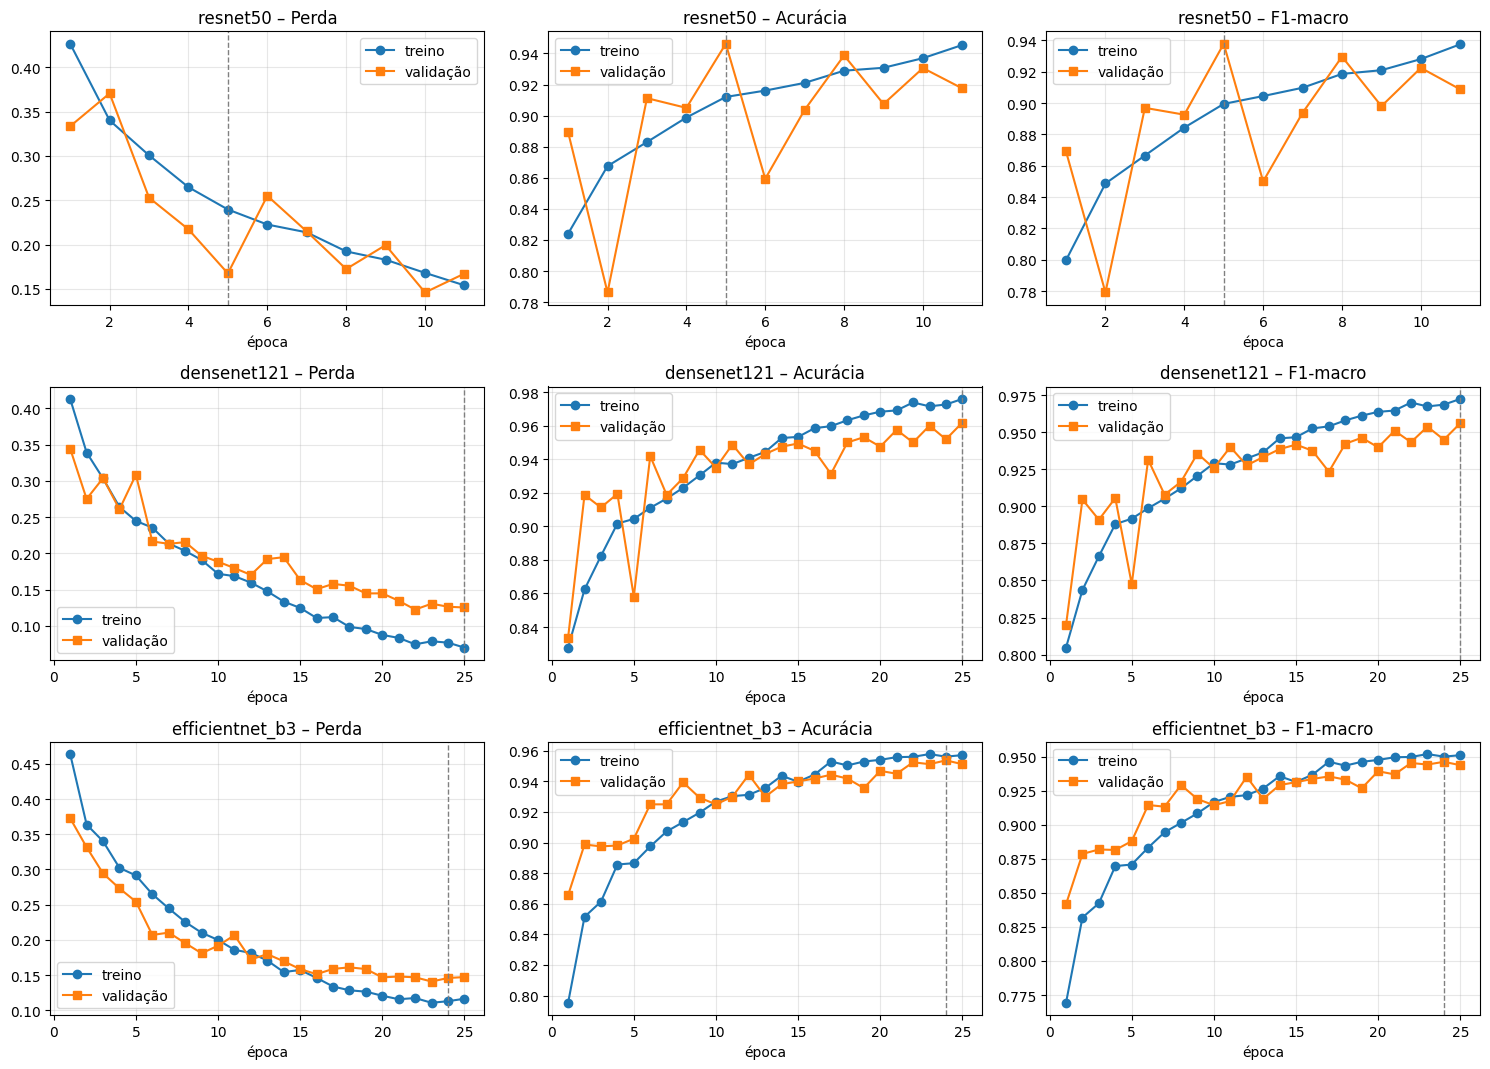

In [18]:
fig, axes = plt.subplots(len(MODEL_NAMES), 3, figsize=(15, 3.6 * len(MODEL_NAMES)), squeeze=False)
for i, name in enumerate(MODEL_NAMES):
    h = train_results[name]["history"]
    for j, (met, title) in enumerate([("loss", "Perda"), ("acc", "Acurácia"), ("f1", "F1-macro")]):
        ax = axes[i, j]
        ax.plot(h.epoch, h[f"train_{met}"], "o-", label="treino")
        ax.plot(h.epoch, h[f"val_{met}"], "s-", label="validação")
        ax.axvline(train_results[name]["best_epoch"], ls="--", c="gray", lw=1)
        ax.set_title(f"{name} – {title}"); ax.set_xlabel("época"); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.savefig(DIRS["figures"] / "curvas_aprendizado.png", dpi=150); plt.show()

## 12. Avaliação no conjunto de teste

Para cada arquitetura, o melhor checkpoint (`.pth`) é carregado e avaliado **uma única vez** no teste. São gerados:

- **Classification Report completo** (precisão, recall, F1 e suporte por classe, além das médias **macro** e **weighted**), salvo em `.txt` e `.csv`;
- **matriz de confusão** (absoluta e normalizada);
- métricas adicionais: acurácia, acurácia balanceada, sensibilidade (recall de ALL), especificidade (recall de HEM) e ROC-AUC.

**Estratégia de agregação:** o problema é binário e desbalanceado. Por isso são relatadas a média **macro** (cada classe pesa igual,
penalizando erros na classe minoritária HEM) e a **weighted** (ponderada pelo suporte, comparável ao F1 ponderado do desafio C-NMC).
A métrica principal de comparação é o **F1-macro**.

In [ ]:
@torch.no_grad()
def predict(model, loader):
    model.eval()
    probs, ys, idxs = [], [], []
    for x, y, i in tqdm(loader, leave=False, desc="teste"):
        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            logits = model(x.to(DEVICE, non_blocking=True))
        probs.append(torch.softmax(logits.float(), 1).cpu()); ys.append(y); idxs.append(i)
    return torch.cat(ys).numpy(), torch.cat(probs).numpy(), torch.cat(idxs).numpy()

def load_checkpoint(name):
    ckpt = torch.load(DIRS["models"] / f"{name}_best.pth", map_location=DEVICE)
    model = build_model(name, pretrained=False)
    model.load_state_dict(ckpt["state_dict"])
    return model.to(DEVICE).eval()

@torch.no_grad()
def inference_time_ms(model, n_iter=20):
    x = torch.randn(1, 3, IMG_SIZE, IMG_SIZE, device=DEVICE)
    for _ in range(3): model(x)
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    for _ in range(n_iter): model(x)
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    return 1000 * (time.time() - t0) / n_iter

test_results, summary_rows = {}, []
for name in MODEL_NAMES:
    model = load_checkpoint(name)
    y_true, probs, idx = predict(model, test_loader)
    y_pred = probs.argmax(1)
    test_results[name] = dict(y_true=y_true, y_pred=y_pred, probs=probs, idx=idx)

    #Classification Report completo
    rep_txt = classification_report(y_true, y_pred, labels=[0, 1], target_names=CLASS_LABELS, digits=4, zero_division=0)
    rep_dict = classification_report(y_true, y_pred, labels=[0, 1], target_names=CLASS_LABELS, digits=4,
                                     zero_division=0, output_dict=True)
    print("=" * 70, f"\nClassification Report – {name}\n" + "=" * 70)
    print(rep_txt)
    (DIRS["reports"] / f"classification_report_{name}.txt").write_text(rep_txt)
    pd.DataFrame(rep_dict).T.to_csv(DIRS["reports"] / f"classification_report_{name}.csv")

    #Métricas
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    p_ma, r_ma, f_ma, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    p_w, r_w, f_w, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
    try:
        auc = roc_auc_score(y_true, probs[:, 1])
    except ValueError:
        auc = float("nan")
    summary_rows.append(dict(
        modelo=name, acuracia=accuracy_score(y_true, y_pred), acuracia_balanceada=balanced_accuracy_score(y_true, y_pred),
        precisao_macro=p_ma, recall_macro=r_ma, f1_macro=f_ma,
        precisao_weighted=p_w, recall_weighted=r_w, f1_weighted=f_w,
        sensibilidade_ALL=tp / (tp + fn) if tp + fn else 0, especificidade_HEM=tn / (tn + fp) if tn + fp else 0,
        roc_auc=auc, parametros_M=arch_info.loc[name, "parametros_M"],
        tempo_treino_min=train_results[name]["train_time_min"], melhor_epoca=train_results[name]["best_epoch"],
        inferencia_ms_img=inference_time_ms(model)))

    # Predições por imagem
    pd.DataFrame(dict(path=test_df.path.values[idx], subject=test_df.subject.values[idx], y_true=y_true, y_pred=y_pred,
                      prob_all=probs[:, 1], correto=y_true == y_pred)).to_csv(
        DIRS["reports"] / f"predicoes_teste_{name}.csv", index=False)
    del model

results_df = pd.DataFrame(summary_rows).set_index("modelo")
results_df.to_csv(DIRS["reports"] / "comparacao_modelos.csv")
display(results_df.round(4))

teste:   0%|          | 0/59 [00:00<?, ?it/s]

Classification Report – resnet50
                 precision    recall  f1-score   support

   HEM (normal)     0.7872    0.5880    0.6731       648
ALL (leucêmica)     0.8069    0.9155    0.8578      1219

       accuracy                         0.8018      1867
      macro avg     0.7971    0.7517    0.7655      1867
   weighted avg     0.8001    0.8018    0.7937      1867



teste:   0%|          | 0/59 [00:00<?, ?it/s]

Classification Report – densenet121
                 precision    recall  f1-score   support

   HEM (normal)     0.7828    0.6898    0.7334       648
ALL (leucêmica)     0.8449    0.8983    0.8708      1219

       accuracy                         0.8259      1867
      macro avg     0.8139    0.7940    0.8021      1867
   weighted avg     0.8234    0.8259    0.8231      1867



teste:   0%|          | 0/59 [00:00<?, ?it/s]

Classification Report – efficientnet_b3
                 precision    recall  f1-score   support

   HEM (normal)     0.7855    0.6836    0.7310       648
ALL (leucêmica)     0.8427    0.9007    0.8707      1219

       accuracy                         0.8254      1867
      macro avg     0.8141    0.7922    0.8009      1867
   weighted avg     0.8228    0.8254    0.8222      1867



,acuracia,acuracia_balanceada,precisao_macro,recall_macro,f1_macro,precisao_weighted,recall_weighted,f1_weighted,sensibilidade_ALL,especificidade_HEM,roc_auc,parametros_M,tempo_treino_min,melhor_epoca,inferencia_ms_img
modelo,,,,,,,,,,,,,,,
resnet50,0.8018,0.7517,0.7971,0.7517,0.7655,0.8001,0.8018,0.7937,0.9155,0.5880,0.8732,23.51,15.8441,5,6.4183
densenet121,0.8259,0.7940,0.8139,0.7940,0.8021,0.8234,0.8259,0.8231,0.8983,0.6898,0.8942,6.96,37.1459,25,18.1124
efficientnet_b3,0.8254,0.7922,0.8141,0.7922,0.8009,0.8228,0.8254,0.8222,0.9007,0.6836,0.8864,10.70,37.0371,24,14.0056


In [ ]:
# Matrizes de confusão
fig, axes = plt.subplots(2, len(MODEL_NAMES), figsize=(5 * len(MODEL_NAMES), 9), squeeze=False)
for j, name in enumerate(MODEL_NAMES):
    r = test_results[name]
    cm = confusion_matrix(r["y_true"], r["y_pred"], labels=[0, 1])
    cmn = cm / cm.sum(1, keepdims=True).clip(min=1)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0, j],
                xticklabels=CLASS_LABELS, yticklabels=CLASS_LABELS)
    sns.heatmap(cmn, annot=True, fmt=".2%", cmap="Blues", cbar=False, ax=axes[1, j], vmin=0, vmax=1,
                xticklabels=CLASS_LABELS, yticklabels=CLASS_LABELS)
    for i, t in enumerate(["absoluta", "normalizada por linha"]):
        axes[i, j].set_title(f"{name} – {t}"); axes[i, j].set_xlabel("Predito"); axes[i, j].set_ylabel("Real")
plt.tight_layout(); plt.savefig(DIRS["figures"] / "matrizes_confusao.png", dpi=150); plt.show()

# Curvas ROC
plt.figure(figsize=(5.5, 5))
for name in MODEL_NAMES:
    r = test_results[name]
    if len(np.unique(r["y_true"])) == 2:
        fpr, tpr, _ = roc_curve(r["y_true"], r["probs"][:, 1])
        plt.plot(fpr, tpr, label=f"{name} (AUC = {results_df.loc[name, 'roc_auc']:.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.xlabel("1 − Especificidade (FPR)"); plt.ylabel("Sensibilidade (TPR)"); plt.title("Curvas ROC – teste")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig(DIRS["figures"] / "curvas_roc.png", dpi=150); plt.show()

## 13. Análise qualitativa: amostras corretamente e incorretamente classificadas

Para cada arquitetura, é salva uma amostra aleatória (semente fixa) de imagens **corretas** e **incorretas**, balanceada entre as
classes quando possível. O título de cada imagem mostra a classe real, a classe predita e a confiança do modelo. As figuras ficam em
`outputs/figures/` e as imagens originais são copiadas para `outputs/samples/<modelo>/{corretas,incorretas}/`.

In [ ]:
N_SAMPLES = 8   # por grupo (corretas / incorretas)

def pick_samples(y_true, mask, n, seed=SEED):
    rng = np.random.RandomState(seed)
    chosen = []
    for c in [0, 1]:
        pool = np.where(mask & (y_true == c))[0]
        chosen += list(rng.choice(pool, min(len(pool), n // 2), replace=False))
    rest = np.setdiff1d(np.where(mask)[0], chosen)
    if len(chosen) < n and len(rest):
        chosen += list(rng.choice(rest, min(len(rest), n - len(chosen)), replace=False))
    return chosen

def show_samples(name, positions, kind):
    r = test_results[name]
    if len(positions) == 0:
        print(f"[{name}] nenhuma amostra {kind}."); return
    cols = 4; rows = int(np.ceil(len(positions) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(3.3 * cols, 4.0 * rows), squeeze=False)
    out_dir = DIRS["samples"] / name / kind; out_dir.mkdir(parents=True, exist_ok=True)
    for ax in axes.ravel(): ax.axis("off")
    for ax, pos in zip(axes.ravel(), positions):
        path = test_df.path.values[r["idx"][pos]]
        yt, yp, conf = r["y_true"][pos], r["y_pred"][pos], r["probs"][pos].max()
        ax.imshow(Image.open(path).convert("RGB"))
        ax.set_title(f"Real: {CLASS_NAMES[yt].upper()} | Pred: {CLASS_NAMES[yp].upper()}\nconfiança {conf:.2%}",
                     fontsize=9, color="green" if yt == yp else "red")
        shutil.copy(path, out_dir / f"real-{CLASS_NAMES[yt]}_pred-{CLASS_NAMES[yp]}_{conf:.2f}_{Path(path).name}")
    plt.suptitle(f"{name} – amostras {kind}", fontsize=13); plt.tight_layout()
    plt.savefig(DIRS["figures"] / f"amostras_{kind}_{name}.png", dpi=150); plt.show()

for name in MODEL_NAMES:
    r = test_results[name]
    ok = r["y_true"] == r["y_pred"]
    show_samples(name, pick_samples(r["y_true"], ok, N_SAMPLES), "corretas")
    show_samples(name, pick_samples(r["y_true"], ~ok, N_SAMPLES), "incorretas")
    fn = int(((r["y_true"] == 1) & (r["y_pred"] == 0)).sum()); fp = int(((r["y_true"] == 0) & (r["y_pred"] == 1)).sum())
    print(f"[{name}] erros: {(~ok).sum()} | falsos negativos (ALL->HEM): {fn} | falsos positivos (HEM->ALL): {fp}")

Distribuição de quantos modelos erram cada imagem: {np.int64(0): np.int64(1302), np.int64(1): np.int64(264), np.int64(2): np.int64(146), np.int64(3): np.int64(155)}
Imagens erradas por todos os 3 modelos: 155


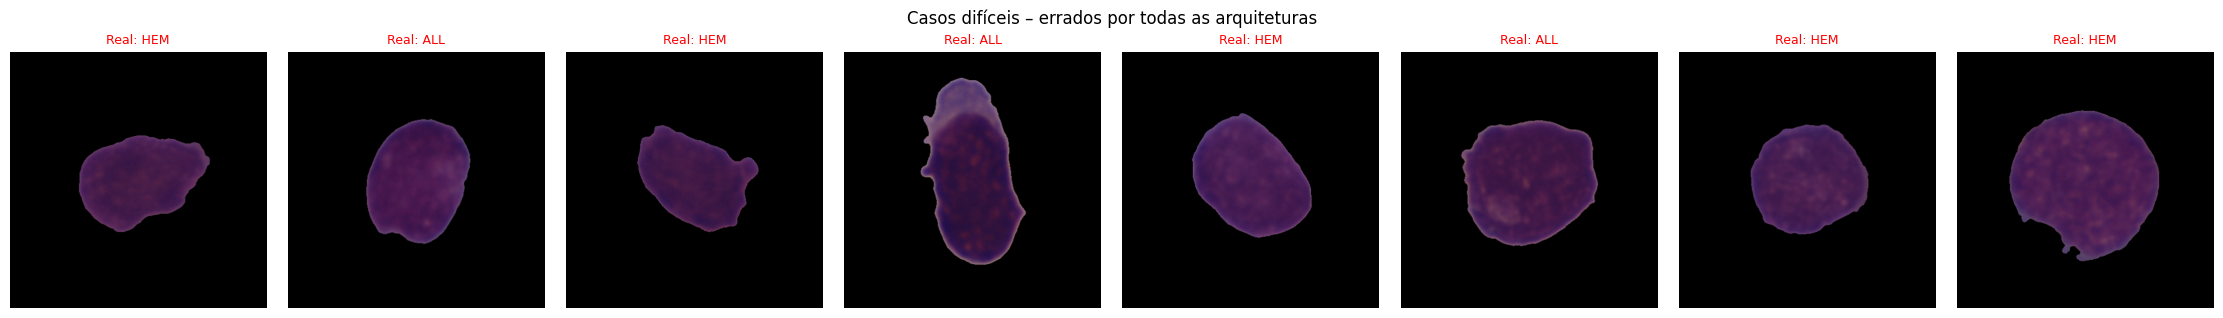


Taxa de erro por paciente (densenet121) – 10 piores:


,taxa_erro
subject,
UID_H25,0.789474
UID_60,0.611111
UID_H29,0.605263
UID_H33,0.600000
UID_H28,0.555556
UID_H34,0.500000
UID_H35,0.483871
UID_61,0.428571
UID_H50,0.413793


In [ ]:
#imagens que TODAS as arquiteturas erraram
ref_idx = test_results[MODEL_NAMES[0]]["idx"]
wrong = np.stack([(test_results[n]["y_true"] != test_results[n]["y_pred"]) for n in MODEL_NAMES])
assert all((test_results[n]["idx"] == ref_idx).all() for n in MODEL_NAMES)
n_wrong = wrong.sum(0)
print("Distribuição de quantos modelos erram cada imagem:", dict(zip(*np.unique(n_wrong, return_counts=True))))
print(f"Imagens erradas por todos os {len(MODEL_NAMES)} modelos: {(n_wrong == len(MODEL_NAMES)).sum()}")

hard = np.where(n_wrong == len(MODEL_NAMES))[0]
if len(hard):
    sel = np.random.RandomState(SEED).choice(hard, min(8, len(hard)), replace=False)
    fig, axes = plt.subplots(1, len(sel), figsize=(2.8 * len(sel), 3.2), squeeze=False)
    yt_all = test_results[MODEL_NAMES[0]]["y_true"]
    for ax, pos in zip(axes.ravel(), sel):
        ax.imshow(Image.open(test_df.path.values[ref_idx[pos]]).convert("RGB")); ax.axis("off")
        ax.set_title(f"Real: {CLASS_NAMES[yt_all[pos]].upper()}", color="red", fontsize=9)
    plt.suptitle("Casos difíceis – errados por todas as arquiteturas"); plt.tight_layout()
    plt.savefig(DIRS["figures"] / "casos_dificeis_todos_modelos.png", dpi=150); plt.show()

# Taxa de erro por paciente (variação entre indivíduos)
best_name = results_df.f1_macro.idxmax()
pred_best = pd.read_csv(DIRS["reports"] / f"predicoes_teste_{best_name}.csv")
err_subject = (1 - pred_best.groupby("subject").correto.mean()).sort_values(ascending=False)
print(f"\nTaxa de erro por paciente ({best_name}) – 10 piores:")
display(err_subject.head(10).to_frame("taxa_erro"))

## 14. Questão experimental: comparação entre arquiteturas

**Pergunta:** *sob o mesmo protocolo (transfer learning do ImageNet, mesmo aumento de dados, hiperparâmetros, semente e divisão de dados),
qual arquitetura (ResNet50, DenseNet121 ou EfficientNet-B3) generaliza melhor para pacientes não vistos, e a diferença é
estatisticamente significativa?*

A significância é avaliada com o **teste de McNemar exato** sobre as predições pareadas no mesmo conjunto de teste
(H₀: os dois modelos têm a mesma taxa de erro; α = 0,05). O teste considera só as discordâncias: *b* = imagens que o modelo A acerta e
o B erra; *c* = o contrário.

In [ ]:
metrics_plot = ["acuracia", "acuracia_balanceada", "f1_macro", "f1_weighted", "sensibilidade_ALL", "especificidade_HEM", "roc_auc"]
ax = results_df[metrics_plot].T.plot.bar(figsize=(13, 4.5), width=0.8)
ax.set_ylim(0, 1.05); ax.set_ylabel("valor"); ax.set_title("Comparação entre arquiteturas – conjunto de teste")
ax.set_xticklabels(metrics_plot, rotation=20); ax.grid(axis="y", alpha=.3); ax.legend(loc="lower right")
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=7, rotation=90, padding=2)
plt.tight_layout(); plt.savefig(DIRS["figures"] / "comparacao_metricas.png", dpi=150); plt.show()

#Custo computacional x desempenho
fig, ax = plt.subplots(figsize=(6, 4))
for name in MODEL_NAMES:
    ax.scatter(results_df.loc[name, "parametros_M"], results_df.loc[name, "f1_macro"], s=120)
    ax.annotate(name, (results_df.loc[name, "parametros_M"], results_df.loc[name, "f1_macro"]),
                textcoords="offset points", xytext=(6, 6))
ax.set_xlabel("Parâmetros (milhões)"); ax.set_ylabel("F1-macro (teste)"); ax.grid(alpha=.3)
ax.set_title("Desempenho x tamanho do modelo"); plt.tight_layout()
plt.savefig(DIRS["figures"] / "desempenho_vs_parametros.png", dpi=150); plt.show()

display(results_df[["f1_macro", "acuracia_balanceada", "roc_auc", "parametros_M", "tempo_treino_min",
                    "inferencia_ms_img"]].sort_values("f1_macro", ascending=False).round(4))

In [ ]:
# Teste de McNemar par a par-
def mcnemar_exact(y_true, pred_a, pred_b):
    a_ok, b_ok = pred_a == y_true, pred_b == y_true
    b = int((a_ok & ~b_ok).sum())   # A acerta, B erra
    c = int((~a_ok & b_ok).sum())   # A erra, B acerta
    p = binomtest(b, b + c, 0.5).pvalue if b + c > 0 else 1.0
    return b, c, p

rows = []
for i in range(len(MODEL_NAMES)):
    for j in range(i + 1, len(MODEL_NAMES)):
        a, b_ = MODEL_NAMES[i], MODEL_NAMES[j]
        yt = test_results[a]["y_true"]
        b, c, p = mcnemar_exact(yt, test_results[a]["y_pred"], test_results[b_]["y_pred"])
        rows.append(dict(modelo_A=a, modelo_B=b_, A_acerta_B_erra=b, A_erra_B_acerta=c, p_valor=p,
                         significativo_5pct=p < 0.05,
                         f1_macro_A=results_df.loc[a, "f1_macro"], f1_macro_B=results_df.loc[b_, "f1_macro"]))
mcnemar_df = pd.DataFrame(rows)
mcnemar_df.to_csv(DIRS["reports"] / "mcnemar_pares.csv", index=False)
display(mcnemar_df.round(4))

best = results_df.f1_macro.idxmax()
print(f"Melhor arquitetura no teste (F1-macro): {best} = {results_df.loc[best, 'f1_macro']:.4f}")
for _, r in mcnemar_df.iterrows():
    verdict = "diferença SIGNIFICATIVA" if r.significativo_5pct else "diferença NÃO significativa"
    print(f"  {r.modelo_A} vs {r.modelo_B}: p = {r.p_valor:.4g} -> {verdict} (α = 0,05)")

,modelo_A,modelo_B,A_acerta_B_erra,A_erra_B_acerta,p_valor,significativo_5pct,f1_macro_A,f1_macro_B
0,resnet50,densenet121,126,171,0.0106,True,0.7655,0.8021
1,resnet50,efficientnet_b3,125,169,0.0120,True,0.7655,0.8009
2,densenet121,efficientnet_b3,115,114,1.0000,False,0.8021,0.8009


Melhor arquitetura no teste (F1-macro): densenet121 = 0.8021
  resnet50 vs densenet121: p = 0.01055 -> diferença SIGNIFICATIVA (α = 0,05)
  resnet50 vs efficientnet_b3: p = 0.01202 -> diferença SIGNIFICATIVA (α = 0,05)
  densenet121 vs efficientnet_b3: p = 1 -> diferença NÃO significativa (α = 0,05)


In [ ]:
print("Arquivos gerados em", OUTPUT_DIR.resolve())
for p in sorted(OUTPUT_DIR.rglob("*")):
    if p.is_file() and "samples" not in p.parts:
        print(f"  {p.relative_to(OUTPUT_DIR)}  ({p.stat().st_size / 1e6:.2f} MB)")
print("  samples/ ->", sum(1 for _ in DIRS["samples"].rglob("*.bmp")), "imagens de amostra copiadas")

Arquivos gerados em /content/outputs
  figures/amostras_corretas_densenet121.png  (0.36 MB)
  figures/amostras_corretas_efficientnet_b3.png  (0.44 MB)
  figures/amostras_corretas_resnet50.png  (0.41 MB)
  figures/amostras_incorretas_densenet121.png  (0.45 MB)
  figures/amostras_incorretas_efficientnet_b3.png  (0.36 MB)
  figures/amostras_incorretas_resnet50.png  (0.45 MB)
  figures/casos_dificeis_todos_modelos.png  (0.31 MB)
  figures/comparacao_metricas.png  (0.09 MB)
  figures/curvas_aprendizado.png  (0.39 MB)
  figures/curvas_roc.png  (0.07 MB)
  figures/data_augmentation.png  (0.14 MB)
  figures/desempenho_vs_parametros.png  (0.05 MB)
  figures/distribuicao_classes.png  (0.04 MB)
  figures/exemplos_classes.png  (0.30 MB)
  figures/matrizes_confusao.png  (0.12 MB)
  logs/config.json  (0.00 MB)
  logs/history_densenet121.csv  (0.00 MB)
  logs/history_efficientnet_b3.csv  (0.00 MB)
  logs/history_resnet50.csv  (0.00 MB)
  logs/split_test.csv  (0.25 MB)
  logs/split_train.csv  (1.07 MB